<a href="https://colab.research.google.com/github/lakshanya-j/Projects/blob/main/DBSCANClusteringAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (200, 6)

First Five Rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
 5   cluster                 200 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 9.5+ KB

Statistical Summary:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
count,200.000000,200,200.000000,200.000000,200.000000,200.00000
unique,NaN,2,NaN,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000,2.24500
std,57.879185,NaN,13.969007,26.264721,25.823522,1.81423
min,1.000000,NaN,18.000000,15.000000,1.000000,0.00000
25%,50.750000,NaN,28.750000,41.500000,34.750000,1.00000
50%,100.500000,NaN,36.000000,61.500000,50.000000,2.00000
75%,150.250000,NaN,49.000000,78.000000,73.000000,4.00000



Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
cluster                   0
dtype: int64

Missing Values After Cleaning:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
cluster                   0
dtype: int64

Unique Clusters: [-1  0  1  2  3  4  5]
Number of Clusters: 6
Number of Noise Points: 23

Customers in Each Cluster:
DBSCAN_Cluster
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64


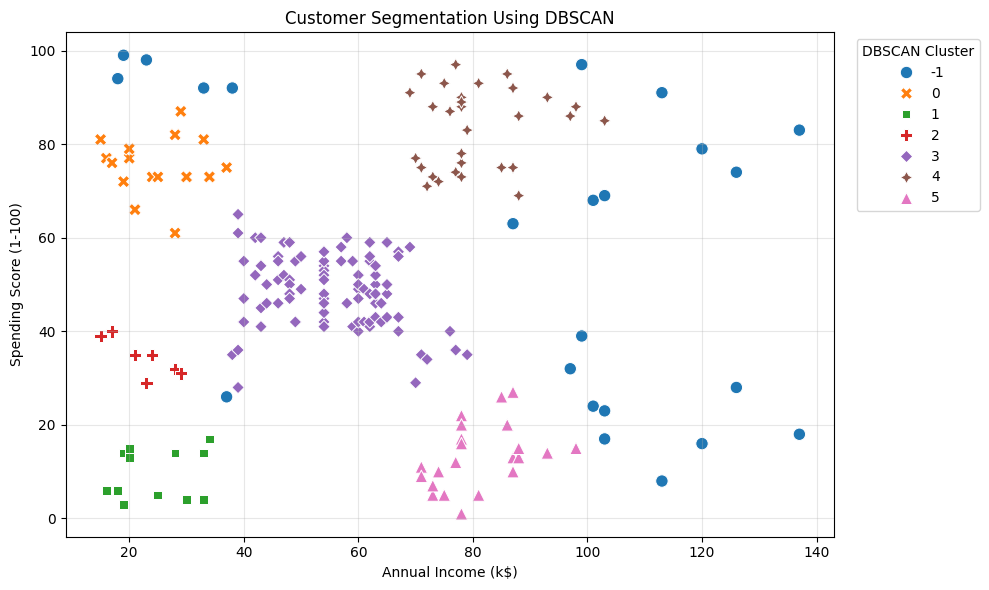


Cluster Summary:


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
DBSCAN_Cluster,,,,
-1,23,34.43,89.26,57.83
0,16,24.81,24.75,75.38
1,12,48.75,24.58,9.58
2,7,36.71,22.43,34.43
3,88,42.88,55.23,48.58
4,31,32.84,80.29,83.19
5,23,41.22,80.96,12.78



Clustered Dataset Saved Successfully!

Conclusion:
The DBSCAN algorithm was applied to the customer dataset using annual income and spending score.
The data was explored, cleaned, and standardized before clustering.
DBSCAN identified customer clusters based on data density and marked outliers as noise.
The scatter plot visualized the resulting clusters.
This dataset is useful for understanding customer segmentation and unsupervised machine learning.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

df = pd.read_csv("customers (1).csv")

print("Dataset Shape:", df.shape)
print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

df = df.drop_duplicates().copy()

numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

features = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

dbscan = DBSCAN(eps=0.35, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

unique_clusters = np.sort(df["DBSCAN_Cluster"].unique())

print("\nUnique Clusters:", unique_clusters)
print("Number of Clusters:", len(set(dbscan.labels_) - {-1}))
print("Number of Noise Points:", np.sum(dbscan.labels_ == -1))

print("\nCustomers in Each Cluster:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=80,
    style="DBSCAN_Cluster"
)

plt.title("Customer Segmentation Using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="DBSCAN Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

cluster_summary = df.groupby("DBSCAN_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("\nCluster Summary:")
display(cluster_summary)

df.to_csv("dbscan_customer_clusters.csv", index=False)

print("\nClustered Dataset Saved Successfully!")

print("""
Conclusion:
The DBSCAN algorithm was applied to the customer dataset using annual income and spending score.
The data was explored, cleaned, and standardized before clustering.
DBSCAN identified customer clusters based on data density and marked outliers as noise.
The scatter plot visualized the resulting clusters.
This dataset is useful for understanding customer segmentation and unsupervised machine learning.
""")

files.download("dbscan_customer_clusters.csv")